# Product Optimization & Revenue Contribution Analysis
## Afficionado Coffee Roasters

### 1. Project Overview

Afficionado Coffee Roasters operates in the specialty coffee retail industry, where understanding product performance is essential for effective menu management and revenue growth.

This project analyzes transaction-level sales data to identify popular products, evaluate revenue contribution, compare product categories, and understand revenue concentration across the menu.

### 2. Project Objectives

The primary objectives of this analysis are to:

- Identify the best-selling and least-selling products.
- Calculate revenue contribution at product and category levels.
- Compare product popularity with revenue generation.
- Identify products that contribute most and least to total revenue.
- Evaluate revenue concentration and potential menu optimization opportunities.
- Develop data-driven recommendations to support product and merchandising decisions.

### 3. Tools and Technologies

- **Python:** Data analysis and computation.
- **Pandas:** Data manipulation and aggregation.
- **NumPy:** Numerical operations.
- **Matplotlib:** Data visualization.
- **Seaborn:** Statistical visualization.
- **Jupyter Notebook:** Interactive analysis and documentation.

### 4. Analytical Approach

The analysis will follow these stages:

1. Data loading and initial inspection.
2. Data quality assessment and cleaning.
3. Transaction-level revenue calculation.
4. Product sales volume and popularity analysis.
5. Product and category revenue contribution analysis.
6. Revenue concentration and Pareto analysis.
7. Data visualization and business recommendations.

### 5. Expected Outcome

The final analysis will provide insights into which products drive sales and revenue, how revenue is distributed across product categories, and which products may require further investigation for potential menu optimization.

In [1]:
# Import the required libraries

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Display all columns when viewing DataFrames
pd.set_option('display.max_columns', None)

# Set a consistent visualization style
sns.set_style("whitegrid")

print("Libraries imported successfully!")

Libraries imported successfully!


In [11]:
# Load the dataset

data_path = "Data/"
file = data_path + "Afficionado_Coffee_Roasters.csv"

df = pd.read_csv(file)

In [12]:
# Initial data inspection

# Basic structure
print("Dataset shape:", df.shape)

print("\nColumn names:")
print(df.columns.tolist())

print("\nFirst 5 rows:")
display(df.head())

Dataset shape: (149116, 11)

Column names:
['transaction_id', 'year', 'transaction_time', 'transaction_qty', 'store_id', 'store_location', 'product_id', 'unit_price', 'product_category', 'product_type', 'product_detail']

First 5 rows:


,transaction_id,year,transaction_time,transaction_qty,store_id,store_location,product_id,unit_price,product_category,product_type,product_detail
0,1,2025,7:06:11,2,5,Lower Manhattan,32,3.0,Coffee,Gourmet brewed coffee,Ethiopia Rg
1,2,2025,7:08:56,2,5,Lower Manhattan,57,3.1,Tea,Brewed Chai tea,Spicy Eye Opener Chai Lg
2,3,2025,7:14:04,2,5,Lower Manhattan,59,4.5,Drinking Chocolate,Hot chocolate,Dark chocolate Lg
3,4,2025,7:20:24,1,5,Lower Manhattan,22,2.0,Coffee,Drip coffee,Our Old Time Diner Blend Sm
4,5,2025,7:22:41,2,5,Lower Manhattan,57,3.1,Tea,Brewed Chai tea,Spicy Eye Opener Chai Lg


In [13]:
# Dataset information

df.info()

<class 'pandas.DataFrame'>
RangeIndex: 149116 entries, 0 to 149115
Data columns (total 11 columns):
 #   Column            Non-Null Count   Dtype  
---  ------            --------------   -----  
 0   transaction_id    149116 non-null  int64  
 1   year              149116 non-null  int64  
 2   transaction_time  149116 non-null  str    
 3   transaction_qty   149116 non-null  int64  
 4   store_id          149116 non-null  int64  
 5   store_location    149116 non-null  str    
 6   product_id        149116 non-null  int64  
 7   unit_price        149116 non-null  float64
 8   product_category  149116 non-null  str    
 9   product_type      149116 non-null  str    
 10  product_detail    149116 non-null  str    
dtypes: float64(1), int64(5), str(5)
memory usage: 20.9 MB


In [14]:
# Numerical summary

display(df.describe().T)

,count,mean,std,min,25%,50%,75%,max
transaction_id,149116.0,74737.371872,43153.600016,1.0,37335.75,74727.5,112094.25,149456.0
year,149116.0,2025.000000,0.000000,2025.0,2025.00,2025.0,2025.00,2025.0
transaction_qty,149116.0,1.438276,0.542509,1.0,1.00,1.0,2.00,8.0
store_id,149116.0,5.342063,2.074241,3.0,3.00,5.0,8.00,8.0
product_id,149116.0,47.918607,17.930020,1.0,33.00,47.0,60.00,87.0
unit_price,149116.0,3.382219,2.658723,0.8,2.50,3.0,3.75,45.0


In [15]:
# Categorical / object columns

display(df.describe(include='object').T)

C:\Users\ASUS\AppData\Local\Temp\ipykernel_11988\2697157355.py:3: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  display(df.describe(include='object').T)


,count,unique,top,freq
transaction_time,149116,25762,9:31:15,41
store_location,149116,3,Hell's Kitchen,50735
product_category,149116,9,Coffee,58416
product_type,149116,29,Brewed Chai tea,17183
product_detail,149116,80,Chocolate Croissant,3076


In [16]:
# Data quality checks

# Missing values
missing = df.isnull().sum()

print("Missing values by column:")
display(missing[missing > 0])

Missing values by column:


Series([], dtype: int64)

In [17]:
# Duplicate transactions
print("Duplicate rows:", df.duplicated().sum())

print("Duplicate transaction IDs:", 
      df['transaction_id'].duplicated().sum())

Duplicate rows: 0
Duplicate transaction IDs: 0


In [18]:
# Unique values
print("Unique values per column:")
display(df.nunique().sort_values())

Unique values per column:


year                     1
store_id                 3
store_location           3
transaction_qty          6
product_category         9
product_type            29
unit_price              41
product_id              80
product_detail          80
transaction_time     25762
transaction_id      149116
dtype: int64

In [19]:
# Basic validity checks
print("Years:", sorted(df['year'].unique()))
print("Stores:", sorted(df['store_id'].unique()))
print("Product categories:", df['product_category'].unique())
print("Transaction quantity range:", 
      df['transaction_qty'].min(), "to", df['transaction_qty'].max())
print("Unit price range:", 
      df['unit_price'].min(), "to", df['unit_price'].max())

Years: [np.int64(2025)]
Stores: [np.int64(3), np.int64(5), np.int64(8)]
Product categories: <ArrowStringArray>
[            'Coffee',                'Tea', 'Drinking Chocolate',
             'Bakery',           'Flavours',          'Loose Tea',
       'Coffee beans', 'Packaged Chocolate',            'Branded']
Length: 9, dtype: str
Transaction quantity range: 1 to 8
Unit price range: 0.8 to 45.0


## 3. Data Quality Assessment
3.1 What have we learned?
Based on our output:

| Check | Result | Interpretation |
|---|---|---|
| Total records | 149,116 | A substantial transaction-level dataset |
| Total columns | 11 | Contains transaction, product, store, and pricing information |
| Missing values | 0 | No missing values detected |
| Duplicate rows | 0 | No completely duplicated records detected |
| Duplicate transaction IDs | 0 | Every transaction ID is unique |
| Transaction year | 2025 | All records belong to the same year |
| Stores | 3 | Three store IDs are present |
| Product categories | 9 | The dataset contains nine product categories |
| Product IDs | 80 unique | 80 distinct product IDs are present |
| Transaction quantity | 1–8 | All recorded quantities are positive |
| Unit price | 0.80–45.00 | Prices vary considerably across products |

## 4. Data Validation

The dataset contains 149,116 records with no missing values or completely duplicated rows. Before calculating revenue, additional validation is required to confirm that transaction quantities and unit prices are valid, product identifiers are consistent, and store information is reliable.

These checks will help prevent data quality issues from affecting product rankings and revenue contribution calculations.

In [20]:
# 1. Check for non-positive transaction quantities
print("Non-positive quantities:",
      (df['transaction_qty'] <= 0).sum())

# 2. Check for non-positive unit prices
print("Non-positive unit prices:",
      (df['unit_price'] <= 0).sum())

# 3. Check whether each product ID maps to one product detail
product_mapping = df.groupby('product_id')['product_detail'].nunique()

print("Product IDs mapped to multiple product details:",
      (product_mapping > 1).sum())

# 4. Check whether each product detail maps to multiple product IDs
detail_mapping = df.groupby('product_detail')['product_id'].nunique()

print("Product details mapped to multiple product IDs:",
      (detail_mapping > 1).sum())

# 5. Check whether store IDs consistently map to store locations
store_mapping = df.groupby('store_id')['store_location'].nunique()

print("Store IDs mapped to multiple locations:",
      (store_mapping > 1).sum())

Non-positive quantities: 0
Non-positive unit prices: 0
Product IDs mapped to multiple product details: 0
Product details mapped to multiple product IDs: 0
Store IDs mapped to multiple locations: 0


## 5. Revenue Calculation

Revenue is calculated at the individual record level by multiplying the quantity purchased by the unit price.

This metric will be used to evaluate product performance, compare revenue across categories, and identify products that contribute most significantly to total sales revenue.

In [21]:
# Step 5: Revenue Calculation

# Calculate revenue for each transaction record

df['revenue'] = df['transaction_qty'] * df['unit_price']

# Display the first five rows
display(df[['transaction_id',
            'transaction_qty',
            'unit_price',
            'revenue']].head())

,transaction_id,transaction_qty,unit_price,revenue
0,1,2,3.0,6.0
1,2,2,3.1,6.2
2,3,2,4.5,9.0
3,4,1,2.0,2.0
4,5,2,3.1,6.2


In [22]:
# Calculate total sales revenue

total_revenue = df['revenue'].sum()

print(f"Total Revenue: {total_revenue:,.2f}")

Total Revenue: 698,812.33


## 6. Product Popularity Analysis

Product popularity is measured using the total number of units sold. Analyzing sales volume helps identify frequently purchased products and products with relatively low demand.

In this section, transaction quantities will be aggregated by product ID and product detail. The resulting rankings will help distinguish high-demand products from potential underperformers.

In [23]:
# Aggregate sales quantity by product

product_sales = (
    df.groupby(['product_id', 'product_detail'])
      .agg(
          total_units_sold=('transaction_qty', 'sum'),
          total_transactions=('transaction_id', 'count'),
          total_revenue=('revenue', 'sum')
      )
      .reset_index()
)

# Rank products by sales volume
product_sales = product_sales.sort_values(
    by='total_units_sold',
    ascending=False
).reset_index(drop=True)

# Display the top 10 products
display(product_sales.head(10))

,product_id,product_detail,total_units_sold,total_transactions,total_revenue
0,50,Earl Grey Rg,4708,3053,11770.00
1,59,Dark chocolate Lg,4668,3029,21006.00
2,54,Morning Sunrise Chai Rg,4643,3026,11607.50
3,38,Latte,4602,2990,17257.50
4,44,Peppermint Rg,4564,2949,11410.00
5,29,Columbian Medium Roast Rg,4547,3013,11367.50
6,52,Traditional Blend Chai Rg,4512,2955,11280.00
7,39,Latte Rg,4497,2896,19112.25
8,22,Our Old Time Diner Blend Sm,4484,2919,8968.00
9,46,Serenity Green Tea Rg,4477,2921,11192.50


In [24]:
# Display the 10 least-selling products

display(
    product_sales.sort_values(
        by='total_units_sold',
        ascending=True
    ).head(10)
)

,product_id,product_detail,total_units_sold,total_transactions,total_revenue
79,19,Dark chocolate,118,118,755.20
78,18,Spicy Eye Opener Chai,122,122,1335.90
77,10,Guatemalan Sustainably Grown,134,134,1340.00
76,14,Earl Grey,142,142,1270.90
75,7,Jamacian Coffee River,146,146,2883.50
73,21,Chili Mayan,148,148,1972.84
74,5,Columbian Medium Roast,148,148,2220.00
72,4,Primo Espresso Roast,150,150,3067.50
71,11,Lemon Grass,152,152,1360.40
69,16,Traditional Blend Chai,153,153,1369.35


## 7. Revenue Contribution Analysis

Sales volume alone does not fully explain product performance. Products with similar sales volumes can generate different amounts of revenue because of differences in unit prices.

This section evaluates the revenue generated by each product and calculates its percentage contribution to total revenue. Products will then be ranked by revenue to identify the most financially significant items in the menu.

In [25]:
# Calculate total revenue across all products

total_revenue = product_sales['total_revenue'].sum()

# Calculate each product's revenue contribution (%)

product_sales['revenue_contribution_pct'] = (
    product_sales['total_revenue'] / total_revenue
) * 100

# Rank products by revenue

product_sales = product_sales.sort_values(
    by='total_revenue',
    ascending=False
).reset_index(drop=True)

# Display the top 10 revenue-generating products

display(
    product_sales[
        [
            'product_id',
            'product_detail',
            'total_units_sold',
            'total_revenue',
            'revenue_contribution_pct'
        ]
    ].head(10).round(2)
)

,product_id,product_detail,total_units_sold,total_revenue,revenue_contribution_pct
0,61,Sustainably Grown Organic Lg,4453,21151.75,3.03
1,59,Dark chocolate Lg,4668,21006.00,3.01
2,39,Latte Rg,4497,19112.25,2.73
3,41,Cappuccino Lg,4151,17641.75,2.52
4,55,Morning Sunrise Chai Lg,4346,17384.00,2.49
5,38,Latte,4602,17257.50,2.47
6,36,Jamaican Coffee River Lg,4395,16481.25,2.36
7,60,Sustainably Grown Organic Rg,4329,16233.75,2.32
8,40,Cappuccino,4266,15997.50,2.29
9,27,Brazilian Lg,4317,15109.50,2.16


## 8. Product Popularity vs Revenue

This section compares product sales volume with revenue generation to identify products that perform well in terms of both demand and financial contribution. It also highlights products with high sales volume but relatively low revenue, as well as products that generate strong revenue despite lower sales volume.

In [26]:
# Rank products by total units sold
product_sales['volume_rank'] = (
    product_sales['total_units_sold']
    .rank(method='min', ascending=False)
    .astype(int)
)

# Rank products by total revenue
product_sales['revenue_rank'] = (
    product_sales['total_revenue']
    .rank(method='min', ascending=False)
    .astype(int)
)

# Calculate the difference between the two rankings
product_sales['rank_difference'] = (
    product_sales['volume_rank'] - product_sales['revenue_rank']
)

# Display the top 10 products by revenue
display(
    product_sales[
        [
            'product_detail',
            'total_units_sold',
            'volume_rank',
            'total_revenue',
            'revenue_rank',
            'rank_difference'
        ]
    ]
    .sort_values('revenue_rank')
    .head(10)
    .round(2)
)

,product_detail,total_units_sold,volume_rank,total_revenue,revenue_rank,rank_difference
0,Sustainably Grown Organic Lg,4453,11,21151.75,1,10
1,Dark chocolate Lg,4668,2,21006.00,2,0
2,Latte Rg,4497,8,19112.25,3,5
3,Cappuccino Lg,4151,35,17641.75,4,31
4,Morning Sunrise Chai Lg,4346,19,17384.00,5,14
5,Latte,4602,4,17257.50,6,-2
6,Jamaican Coffee River Lg,4395,15,16481.25,7,8
7,Sustainably Grown Organic Rg,4329,20,16233.75,8,12
8,Cappuccino,4266,25,15997.50,9,16
9,Brazilian Lg,4317,22,15109.50,10,12


## 9. Category Revenue Analysis

This section evaluates sales performance across product categories. Total units sold and revenue will be aggregated by category, and each category's percentage contribution to total revenue will be calculated.

The results will help identify the business's main revenue-generating categories and assess its dependence on particular product groups.

In [27]:
# Aggregate sales and revenue by product category

category_sales = (
    df.groupby('product_category')
      .agg(
          total_units_sold=('transaction_qty', 'sum'),
          total_transactions=('transaction_id', 'count'),
          total_revenue=('revenue', 'sum')
      )
      .reset_index()
)

# Calculate category revenue contribution (%)

category_sales['revenue_contribution_pct'] = (
    category_sales['total_revenue'] / df['revenue'].sum()
) * 100

# Rank categories by revenue

category_sales = category_sales.sort_values(
    by='total_revenue',
    ascending=False
).reset_index(drop=True)

# Display the results

display(category_sales.round(2))

,product_category,total_units_sold,total_transactions,total_revenue,revenue_contribution_pct
0,Coffee,89250,58416,269952.45,38.63
1,Tea,69737,45449,196405.95,28.11
2,Bakery,23214,22796,82315.64,11.78
3,Drinking Chocolate,17457,11468,72416.00,10.36
4,Coffee beans,1828,1753,40085.25,5.74
5,Branded,776,747,13607.00,1.95
6,Loose Tea,1210,1210,11213.60,1.60
7,Flavours,10511,6790,8408.80,1.20
8,Packaged Chocolate,487,487,4407.64,0.63


## 10. Category Revenue Visualization

A bar chart is used to compare revenue generated by each product category. This visualization highlights the strongest revenue-generating categories and provides a clear view of the relative financial contribution of each category.

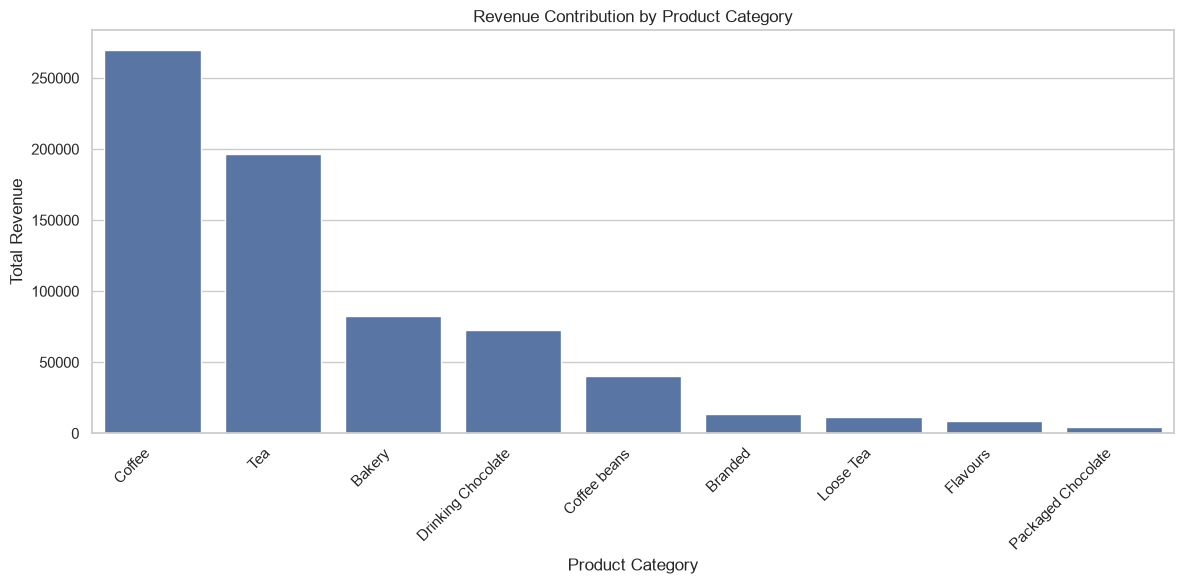

In [28]:
# Plot revenue by product category

plt.figure(figsize=(12, 6))

sns.barplot(
    data=category_sales,
    x='product_category',
    y='total_revenue'
)

plt.title('Revenue Contribution by Product Category')
plt.xlabel('Product Category')
plt.ylabel('Total Revenue')
plt.xticks(rotation=45, ha='right')

plt.tight_layout()
plt.show()

## 11. Product-Type Performance Analysis

This section analyzes revenue and sales volume at the product-type level. It identifies the product types that generate the most revenue and those with comparatively low sales. These insights can help the business evaluate its product assortment and identify opportunities for menu optimization.

In [29]:
# Aggregate sales by product type

type_sales = (
    df.groupby('product_type')
      .agg(
          total_units_sold=('transaction_qty', 'sum'),
          total_transactions=('transaction_id', 'count'),
          total_revenue=('revenue', 'sum')
      )
      .reset_index()
)

# Calculate revenue contribution percentage

type_sales['revenue_contribution_pct'] = (
    type_sales['total_revenue'] / df['revenue'].sum()
) * 100

# Rank product types by revenue

type_sales = type_sales.sort_values(
    by='total_revenue',
    ascending=False
).reset_index(drop=True)

# Display the top 10 product types

display(type_sales.head(10).round(2))

,product_type,total_units_sold,total_transactions,total_revenue,revenue_contribution_pct
0,Barista Espresso,24943,16403,91406.20,13.08
1,Brewed Chai tea,26250,17183,77081.95,11.03
2,Hot chocolate,17457,11468,72416.00,10.36
3,Gourmet brewed coffee,25973,16912,70034.60,10.02
4,Brewed Black tea,17462,11350,47932.00,6.86
5,Brewed herbal tea,17328,11245,47539.50,6.80
6,Premium brewed coffee,12431,8135,38781.15,5.55
7,Organic brewed coffee,13012,8489,37746.50,5.40
8,Scone,10465,10173,36866.12,5.28
9,Drip coffee,12891,8477,31984.00,4.58


## 12. Top Product Types by Revenue

A horizontal bar chart is used to compare revenue across the ten highest-performing product types. This visualization highlights the strongest contributors and makes differences in revenue generation easier to interpret.

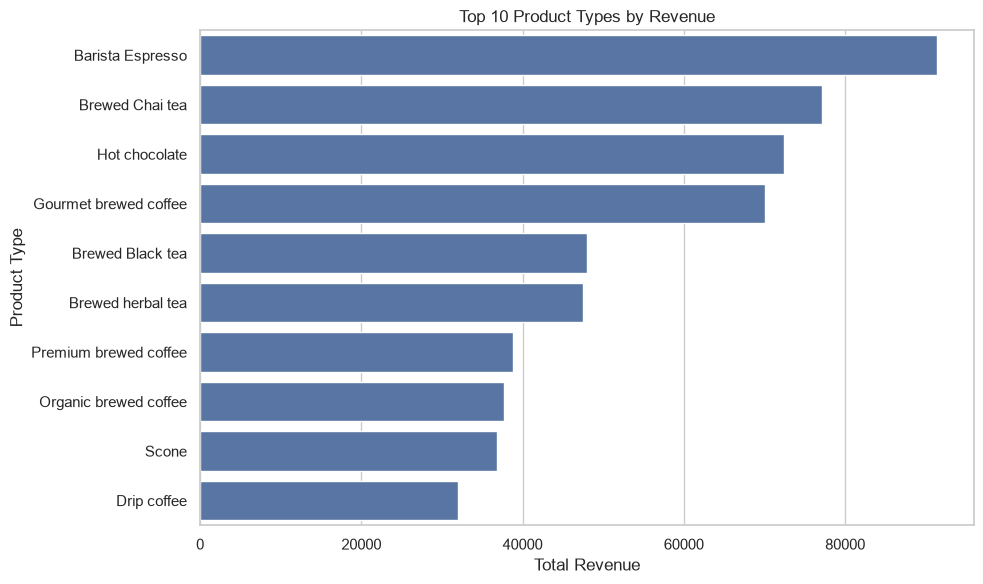

In [31]:
# Select the top 10 product types by revenue

top_10_types = type_sales.head(10).sort_values(
    by='total_revenue',
    ascending=False
)

# Create a horizontal bar chart

plt.figure(figsize=(10, 6))

sns.barplot(
    data=top_10_types,
    x='total_revenue',
    y='product_type'
)

plt.title('Top 10 Product Types by Revenue')
plt.xlabel('Total Revenue')
plt.ylabel('Product Type')

plt.tight_layout()
plt.show()

In [32]:
store_sales = (
    df.groupby(['store_id', 'store_location'])
    .agg(
        total_units_sold=('transaction_qty', 'sum'),
        total_transactions=('transaction_id', 'count'),
        total_revenue=('revenue', 'sum')
    )
    .reset_index()
)

store_sales['revenue_contribution_pct'] = (
    store_sales['total_revenue'] / df['revenue'].sum()
) * 100

store_sales = store_sales.sort_values(
    by='total_revenue',
    ascending=False
).reset_index(drop=True)

store_sales.round(2)

,store_id,store_location,total_units_sold,total_transactions,total_revenue,revenue_contribution_pct
0,8,Hell's Kitchen,71737,50735,236511.17,33.84
1,3,Astoria,70991,50599,232243.91,33.23
2,5,Lower Manhattan,71742,47782,230057.25,32.92


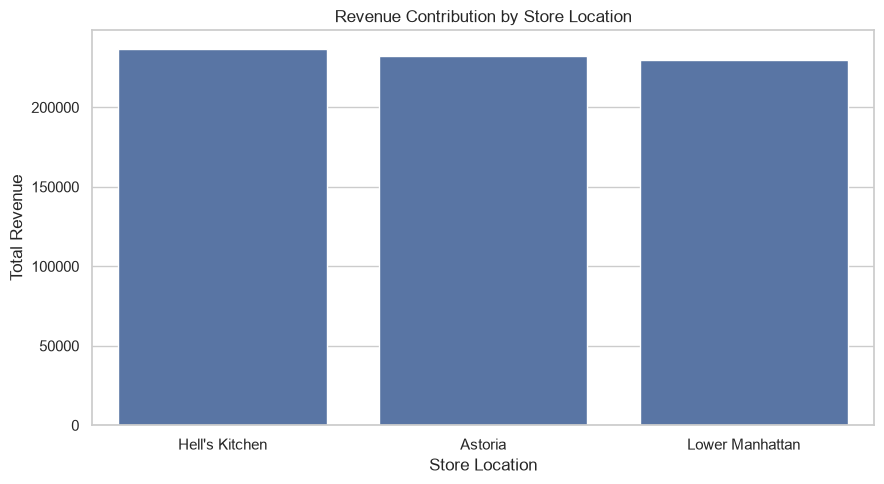

In [33]:
plt.figure(figsize=(9, 5))

sns.barplot(
    data=store_sales,
    x='store_location',
    y='total_revenue'
)

plt.title('Revenue Contribution by Store Location')
plt.xlabel('Store Location')
plt.ylabel('Total Revenue')
plt.tight_layout()
plt.show()

## Step 13: Revenue Analysis by Time of Day

Examine when customers make purchases and when revenue is highest.

In [34]:
df['transaction_time'].head(10)

0    7:06:11
1    7:08:56
2    7:14:04
3    7:20:24
4    7:22:41
5    7:22:41
6    7:25:49
7    7:33:34
8    7:39:13
9    7:39:34
Name: transaction_time, dtype: str

In [35]:
df['transaction_time'] = pd.to_datetime(
    df['transaction_time'],
    format='%H:%M:%S'
).dt.time

df['hour'] = pd.to_datetime(
    df['transaction_time'].astype(str),
    format='%H:%M:%S'
).dt.hour

df[['transaction_time', 'hour']].head(10)

,transaction_time,hour
0,07:06:11,7
1,07:08:56,7
2,07:14:04,7
3,07:20:24,7
4,07:22:41,7
5,07:22:41,7
6,07:25:49,7
7,07:33:34,7
8,07:39:13,7
9,07:39:34,7


## Step 13: Revenue Analysis by Time of Day

### Objective

The objective of this analysis is to understand how sales revenue varies throughout the day and identify the hours that generate the highest revenue for Afficionado Coffee Roasters.

Analyzing transaction times can help the business understand customer purchasing patterns, identify peak sales periods, and make better decisions about staffing, inventory management, and promotional activities.

### Business Questions

- Which hours generate the highest total revenue?
- During which hours are the most units sold?
- Do the busiest hours in terms of sales volume also generate the highest revenue?
- How can the business use these patterns to improve operational efficiency?

### Methodology

The `transaction_time` column contains the time of each transaction. We have extracted the hour into a new column called `hour`.

We will group the data by hour and calculate total revenue, total units sold, and the number of transaction records for each hour. We will then visualize the results to identify peak sales periods.

### Expected Business Value

The findings can help management schedule employees according to customer demand, prepare sufficient stock before busy periods, and identify opportunities to increase sales during quieter hours.

**Note:** This analysis examines hourly patterns across the available dataset. It does not identify monthly or daily trends because separate transaction dates are not available in the current data.

In [36]:
# Group transactions by hour to analyze sales throughout the day.
hourly_sales = (
    df.groupby('hour')
    .agg(
        # Add the revenue generated by all records in each hour.
        total_revenue=('revenue', 'sum'),

        # Add the number of product units sold during each hour.
        total_units_sold=('transaction_qty', 'sum'),

        # Count transaction records recorded during each hour.
        # Each row represents one transaction record in this dataset.
        total_transactions=('transaction_id', 'count')
    )
    .reset_index()
)

# Calculate each hour's percentage contribution to total revenue.
hourly_sales['revenue_contribution_pct'] = (
    hourly_sales['total_revenue'] / df['revenue'].sum()
) * 100

# Sort chronologically so the hours appear in the correct order.
hourly_sales = hourly_sales.sort_values(
    by='hour'
).reset_index(drop=True)

# Display the hourly summary, rounded to two decimal places.
hourly_sales.round(2)

,hour,total_revenue,total_units_sold,total_transactions,revenue_contribution_pct
0,6,21900.27,6865,4594,3.13
1,7,63526.47,19449,13428,9.09
2,8,82699.87,25197,17654,11.83
3,9,85169.53,25370,17764,12.19
4,10,88673.39,26713,18545,12.69
5,11,46319.14,14035,9766,6.63
6,12,40192.79,12690,8708,5.75
7,13,40367.45,12439,8714,5.78
8,14,41304.74,12907,8933,5.91
9,15,41733.10,12923,8979,5.97


In [37]:
# Find the row with the highest total revenue.
peak_revenue_hour = hourly_sales.loc[
    hourly_sales['total_revenue'].idxmax()
]

# Display the hour and its sales performance.
print("Peak Revenue Hour:", int(peak_revenue_hour['hour']))
print("Total Revenue:", round(peak_revenue_hour['total_revenue'], 2))
print(
    "Revenue Contribution (%):",
    round(peak_revenue_hour['revenue_contribution_pct'], 2)
)
print("Total Units Sold:", int(peak_revenue_hour['total_units_sold']))
print("Transaction Records:", int(peak_revenue_hour['total_transactions']))

Peak Revenue Hour: 10
Total Revenue: 88673.39
Revenue Contribution (%): 12.69
Total Units Sold: 26713
Transaction Records: 18545


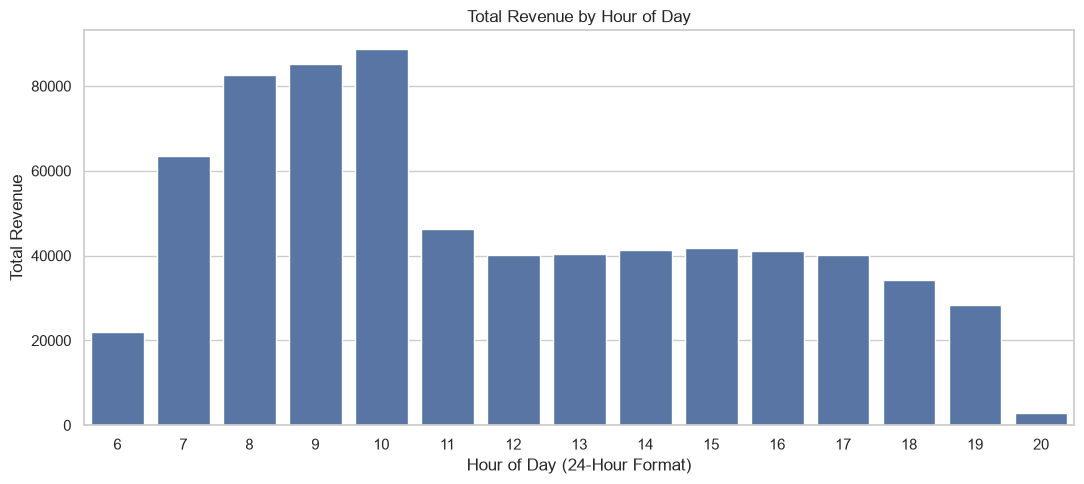

In [38]:
# Create a figure for the hourly revenue chart.
plt.figure(figsize=(11, 5))

# Plot revenue for each hour in chronological order.
sns.barplot(
    data=hourly_sales,
    x='hour',
    y='total_revenue',
    order=hourly_sales['hour']
)

# Add a descriptive title and axis labels.
plt.title('Total Revenue by Hour of Day')
plt.xlabel('Hour of Day (24-Hour Format)')
plt.ylabel('Total Revenue')

# Keep the chart layout neat and display it.
plt.tight_layout()
plt.show()

## Step 14: Product Pricing and Revenue Analysis

### Objective

The objective of this analysis is to examine product pricing alongside sales volume and revenue contribution for Afficionado Coffee Roasters.

### Business Questions

- Which products have the highest and lowest unit prices?
- Do higher-priced products generate more revenue?
- Which products combine strong sales volume with high revenue?
- Are some products generating substantial revenue despite selling fewer units?

### Methodology

We will summarize sales at the product level using the existing `product_sales` DataFrame. The analysis will compare units sold, total revenue, and average revenue per unit.

Average revenue per unit will be calculated as total revenue divided by total units sold. Because product revenue is calculated using quantity multiplied by unit price, this measure represents the weighted average selling price per unit for each product.

### Expected Business Value

The results can help management understand the relationship between price and demand, identify products that contribute strongly to revenue, and select products for further pricing or promotional investigation.

In [39]:
# Make a copy so the existing product_sales summary remains unchanged.
product_pricing = product_sales.copy()

# Calculate the average revenue generated per unit sold.
# This is weighted by the quantity sold for each product.
product_pricing['average_revenue_per_unit'] = (
    product_pricing['total_revenue']
    / product_pricing['total_units_sold']
)

# Sort products from highest to lowest average revenue per unit.
product_pricing = product_pricing.sort_values(
    by='average_revenue_per_unit',
    ascending=False
).reset_index(drop=True)

# Display the products with the highest average revenue per unit.
product_pricing[
    [
        'product_id',
        'product_detail',
        'total_units_sold',
        'total_revenue',
        'average_revenue_per_unit'
    ]
].head(10).round(2)

,product_id,product_detail,total_units_sold,total_revenue,average_revenue_per_unit
0,8,Civet Cat,260,11700.00,45.00
1,81,I Need My Bean! T-shirt,221,6163.00,27.89
2,9,Organic Decaf Blend,206,4657.50,22.61
3,6,Ethiopia,218,4578.00,21.00
4,4,Primo Espresso Roast,150,3067.50,20.45
5,7,Jamacian Coffee River,146,2883.50,19.75
6,1,Brazilian - Organic,214,3852.00,18.00
7,2,Our Old Time Diner Blend,183,3294.00,18.00
8,5,Columbian Medium Roast,148,2220.00,15.00
9,3,Espresso Roast,169,2492.75,14.75


### Analysis of Products with the Lowest Average Revenue per Unit

This analysis identifies products with the lowest average revenue per unit sold.

The purpose is to understand the lower end of the product pricing range and compare these products with their sales volumes and total revenue.

Products with lower average selling prices may still contribute substantially to overall revenue if they sell in large quantities. Therefore, average revenue per unit should be evaluated alongside units sold and total revenue.

The findings may help management assess product positioning, customer demand, and potential opportunities for product bundling or complementary sales. Any pricing changes should be considered only after evaluating costs, demand, and customer response.

In [40]:
# Sort products from lowest to highest average revenue per unit.
lowest_priced_products = product_pricing.sort_values(
    by='average_revenue_per_unit',
    ascending=True
)

# Select the 10 products with the lowest average revenue per unit.
# Display their sales volume and revenue for context.
lowest_priced_products[
    [
        'product_id',
        'product_detail',
        'total_units_sold',
        'total_revenue',
        'average_revenue_per_unit'
    ]
].head(10).round(2)

,product_id,product_detail,total_units_sold,total_revenue,average_revenue_per_unit
79,63,Carmel syrup,2576,2060.8,0.80
78,84,Chocolate syrup,2658,2126.4,0.80
77,64,Hazelnut syrup,2372,1897.6,0.80
76,65,Sugar Free Vanilla syrup,2905,2324.0,0.80
74,22,Our Old Time Diner Blend Sm,4484,8968.0,2.00
75,28,Columbian Medium Roast Sm,4178,8356.0,2.00
72,31,Ethiopia Sm,4433,9752.6,2.20
73,25,Brazilian Sm,4310,9482.0,2.20
71,34,Jamaican Coffee River Sm,4018,9844.1,2.45
63,52,Traditional Blend Chai Rg,4512,11280.0,2.50


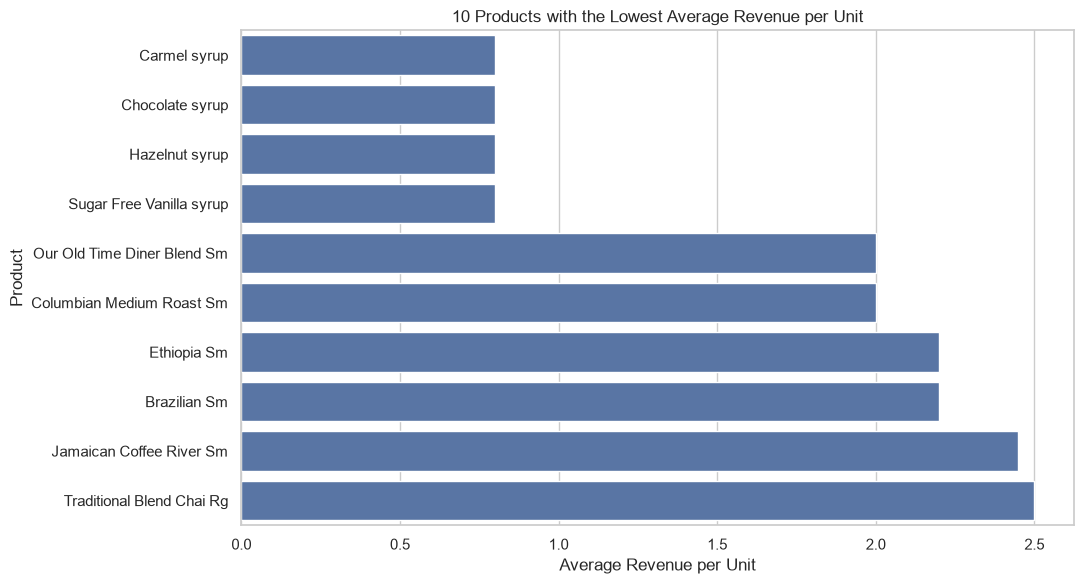

In [42]:
# Select the 10 products with the lowest average revenue per unit.
# Sort from highest to lowest within this selected group so the
# horizontal bar chart displays the lowest-priced products at the top.
lowest_10_plot = (
    lowest_priced_products.head(10)
    .sort_values(
        by='average_revenue_per_unit',
        ascending=True
    )
)

# Set the size of the chart.
plt.figure(figsize=(11, 6))

# Create a horizontal bar chart comparing average revenue per unit.
sns.barplot(
    data=lowest_10_plot,
    x='average_revenue_per_unit',
    y='product_detail',
    order=lowest_10_plot['product_detail']
)

# Add a descriptive title and axis labels.
plt.title('10 Products with the Lowest Average Revenue per Unit')
plt.xlabel('Average Revenue per Unit')
plt.ylabel('Product')

# Adjust spacing so product names are easy to read.
plt.tight_layout()

# Display the chart.
plt.show()

## Step 15: Product Performance Classification

### Objective

The objective of this analysis is to classify products based on their sales volume and revenue contribution to identify high-performing products and products that may require further investigation.

### Business Questions

- Which products perform well in both sales volume and revenue?
- Which products sell many units but generate relatively less revenue?
- Which products generate strong revenue despite having lower sales volumes?
- Which products have relatively low sales volume and low revenue?

### Methodology

We will use the existing `product_sales` DataFrame, which contains total units sold and total revenue for each product.

Products will be compared against the median sales volume and median revenue across all products. This creates four performance groups:

1. **High Volume, High Revenue:** Products performing above the median on both measures.
2. **High Volume, Low Revenue:** Products selling above the median volume but generating below-median revenue.
3. **Low Volume, High Revenue:** Products selling below the median volume but generating above-median revenue.
4. **Low Volume, Low Revenue:** Products below the median on both measures.

The median provides a straightforward, data-driven threshold for this exploratory classification.

### Expected Business Value

This classification can help management prioritize successful products, investigate differences between sales volume and revenue, and identify products that may benefit from additional marketing or product-level review.

### Limitation

This is a relative performance classification, not a profitability analysis. Product costs, profit margins, stock availability, and customer preferences are not included in these groups.

In [43]:
# Calculate the median sales volume across all products.
# Products above this value are considered high-volume for this analysis.
median_units = product_sales['total_units_sold'].median()

# Calculate the median total revenue across all products.
# Products above this value are considered high-revenue for this analysis.
median_revenue = product_sales['total_revenue'].median()

# Display the thresholds so we can understand the classification criteria.
print("Median Units Sold:", median_units)
print("Median Product Revenue:", round(median_revenue, 2))

Median Units Sold: 3629.5
Median Product Revenue: 9225.0


### Product Performance Classification

To compare product sales volume with revenue generation, each product is classified using the median units sold and median revenue calculated in the previous section.

The classification uses two dimensions: sales volume and total revenue.

- **High Volume, High Revenue:** Products above both median thresholds. These products have relatively strong sales volume and revenue.
- **High Volume, Low Revenue:** Products above the median sales-volume threshold but at or below the median revenue threshold. These products sell in relatively high quantities but generate comparatively lower revenue.
- **Low Volume, High Revenue:** Products at or below the median sales-volume threshold but above the median revenue threshold. These products generate relatively strong revenue despite lower sales volume.
- **Low Volume, Low Revenue:** Products at or below both median thresholds. These products may warrant further investigation into demand, product positioning, or availability.

The classification is intended to support product-level prioritization. Being in the low-volume, low-revenue group does not automatically mean a product should be discontinued; additional information about costs, customer demand, and strategic importance would be needed.

In [44]:
# Create a separate DataFrame for product performance classification.
# This preserves the original product_sales summary.
product_performance = product_sales.copy()

# Define a function that assigns a performance group to each product.
def classify_product(row):
    # Check whether the product exceeds both median thresholds.
    if (
        row['total_units_sold'] > median_units
        and row['total_revenue'] > median_revenue
    ):
        return 'High Volume, High Revenue'

    # Check whether sales volume is high but revenue is not above the median.
    elif (
        row['total_units_sold'] > median_units
        and row['total_revenue'] <= median_revenue
    ):
        return 'High Volume, Low Revenue'

    # Check whether revenue is high but sales volume is not above the median.
    elif (
        row['total_units_sold'] <= median_units
        and row['total_revenue'] > median_revenue
    ):
        return 'Low Volume, High Revenue'

    # Products that do not exceed either threshold fall into this group.
    else:
        return 'Low Volume, Low Revenue'

# Apply the classification function to every product.
product_performance['performance_group'] = (
    product_performance.apply(classify_product, axis=1)
)

# Display a sample of the classified products.
product_performance[
    [
        'product_detail',
        'total_units_sold',
        'total_revenue',
        'performance_group'
    ]
].head(10).round(2)

,product_detail,total_units_sold,total_revenue,performance_group
0,Sustainably Grown Organic Lg,4453,21151.75,"High Volume, High Revenue"
1,Dark chocolate Lg,4668,21006.00,"High Volume, High Revenue"
2,Latte Rg,4497,19112.25,"High Volume, High Revenue"
3,Cappuccino Lg,4151,17641.75,"High Volume, High Revenue"
4,Morning Sunrise Chai Lg,4346,17384.00,"High Volume, High Revenue"
5,Latte,4602,17257.50,"High Volume, High Revenue"
6,Jamaican Coffee River Lg,4395,16481.25,"High Volume, High Revenue"
7,Sustainably Grown Organic Rg,4329,16233.75,"High Volume, High Revenue"
8,Cappuccino,4266,15997.50,"High Volume, High Revenue"
9,Brazilian Lg,4317,15109.50,"High Volume, High Revenue"


### Distribution of Products Across Performance Groups

This analysis measures how many products fall into each of the four performance groups.

Counting products in each group helps assess whether the product portfolio is concentrated in high-performing products or contains a substantial number of products with relatively low sales volume and revenue.

The results can help management prioritize products for continued promotion, further investigation, or targeted sales strategies. These classifications are relative to the dataset's median values and should not be interpreted as direct measures of profitability.

In [45]:
# Count the number of products assigned to each performance group.
group_counts = (
    product_performance['performance_group']
    .value_counts()
    .reset_index()
)

# Rename the columns to make the output easier to understand.
group_counts.columns = ['performance_group', 'product_count']

# Calculate the percentage of all products in each group.
group_counts['percentage'] = (
    group_counts['product_count']
    / len(product_performance)
) * 100

# Display the distribution, sorted by number of products.
group_counts = group_counts.sort_values(
    by='product_count',
    ascending=False
).reset_index(drop=True)

group_counts.round(2)

,performance_group,product_count,percentage
0,"High Volume, High Revenue",38,47.5
1,"Low Volume, Low Revenue",38,47.5
2,"Low Volume, High Revenue",2,2.5
3,"High Volume, Low Revenue",2,2.5


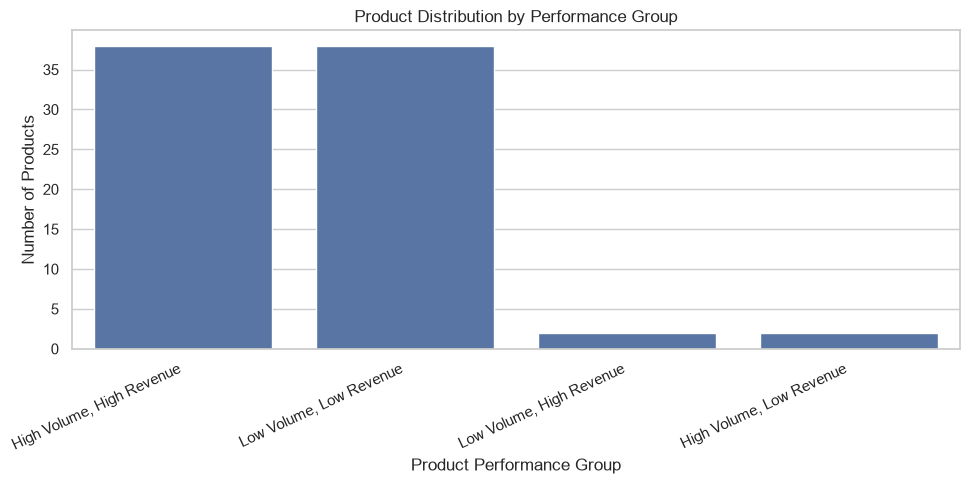

In [46]:
# Create a bar chart showing the number of products in each group.
plt.figure(figsize=(10, 5))

sns.barplot(
    data=group_counts,
    x='performance_group',
    y='product_count'
)

# Add chart title and axis labels.
plt.title('Product Distribution by Performance Group')
plt.xlabel('Product Performance Group')
plt.ylabel('Number of Products')

# Rotate labels for readability.
plt.xticks(rotation=25, ha='right')

plt.tight_layout()
plt.show()

### Results and Interpretation: Product Performance Classification

The product performance classification divides the 80 products into four groups based on median sales volume and median revenue.

#### Key Findings

1. **High Volume, High Revenue:** 38 products (47.5%) perform above the median in both sales volume and revenue. These products represent the strongest relative performers in the portfolio.

2. **Low Volume, Low Revenue:** 38 products (47.5%) fall below or equal to the median thresholds for both measures. These products may require further investigation to understand their sales performance.

3. **Low Volume, High Revenue:** Only 2 products (2.5%) generate above-median revenue despite having below-median sales volume. These products may benefit from further investigation into their pricing and customer demand.

4. **High Volume, Low Revenue:** Only 2 products (2.5%) have above-median sales volume but below-median revenue. Their performance may be influenced by relatively low average selling prices.

#### Business Implications

- **Protect strong performers:** Maintain the availability and visibility of high-volume, high-revenue products.
- **Investigate weaker performers:** Review low-volume, low-revenue products for demand, pricing, stock availability, and customer preferences before considering changes.
- **Study high-revenue niche products:** Examine whether products with lower sales volume but higher revenue offer opportunities for targeted marketing.
- **Review volume-driven products:** Investigate whether high-volume, low-revenue products could benefit from complementary sales or product bundling.

#### Conclusion

The portfolio is divided almost equally between high-volume, high-revenue products and low-volume, low-revenue products. This provides a useful starting point for product optimization. However, the classification is relative to the median and does not measure profitability or establish whether a product should be discontinued.

### Detailed Product-Level Performance Classification

This section identifies the individual products within each performance group.

Examining the product names alongside their sales volume and revenue will help management understand which products contribute strongly to overall performance and which products may need further evaluation.

This detailed breakdown supports more targeted product-level business recommendations.

In [48]:
# Sort products by their performance group and total revenue.
# This makes it easier to compare products within each group.
product_performance_sorted = product_performance.sort_values(
    by=['performance_group', 'total_revenue'],
    ascending=[True, False]
)

# Display the product details and their assigned performance groups.
product_performance_sorted[
    [
        'product_detail',
        'total_units_sold',
        'total_revenue',
        'revenue_contribution_pct',
        'performance_group'
    ]
].round(2)

,product_detail,total_units_sold,total_revenue,revenue_contribution_pct,performance_group
0,Sustainably Grown Organic Lg,4453,21151.75,3.03,"High Volume, High Revenue"
1,Dark chocolate Lg,4668,21006.00,3.01,"High Volume, High Revenue"
2,Latte Rg,4497,19112.25,2.73,"High Volume, High Revenue"
3,Cappuccino Lg,4151,17641.75,2.52,"High Volume, High Revenue"
4,Morning Sunrise Chai Lg,4346,17384.00,2.49,"High Volume, High Revenue"
...,...,...,...,...,...
75,Lemon Grass,152,1360.40,0.19,"Low Volume, Low Revenue"
76,Guatemalan Sustainably Grown,134,1340.00,0.19,"Low Volume, Low Revenue"
77,Spicy Eye Opener Chai,122,1335.90,0.19,"Low Volume, Low Revenue"
78,Earl Grey,142,1270.90,0.18,"Low Volume, Low Revenue"


### Detailed Product-Level Findings

The product-level classification provides a closer look at individual products within the performance groups.

#### Strongest Products

- **Sustainably Grown Organic Lg** is the highest revenue-generating product, contributing 3.03% of total revenue.
- **Dark chocolate Lg** ranks second, contributing 3.01% of total revenue.
- **Latte Rg** ranks third, contributing 2.73% of total revenue.
- These products combine relatively high sales volume with strong revenue generation.

#### Products Requiring Further Investigation

- **Dark chocolate** recorded 118 units sold and generated 755.20 in revenue.
- **Earl Grey** recorded 142 units sold and generated 1,270.90 in revenue.
- **Spicy Eye Opener Chai** recorded 122 units sold and generated 1,335.90 in revenue.
- These products fall within the low-volume, low-revenue group and may warrant further investigation into customer demand, product visibility, and availability.

#### Overall Business Insight

The results demonstrate that product performance varies considerably across the portfolio. A group of products contributes strongly to both sales volume and revenue, while another group performs below the portfolio median on both measures.

Management can use these findings to prioritize inventory planning and marketing efforts while investigating weaker products before making decisions about their future.

## Step 16: Product Category Performance Comparison

### Objective

The objective of this analysis is to evaluate the performance of different product categories based on total revenue, units sold, and revenue contribution.

### Business Questions

- Which product categories generate the highest revenue?
- Which categories contribute the most to total units sold?
- Do high-volume categories also generate high revenue?
- Which categories contribute relatively little to overall revenue?
- Which categories should receive greater attention in inventory and marketing strategies?

### Methodology

We will use the previously created `category_sales` DataFrame to compare the nine product categories.

The analysis will examine total revenue, total units sold, and revenue contribution percentage. We will also compare revenue contribution with sales volume to identify differences in category performance.

### Expected Business Value

This analysis can help management identify the strongest product categories, allocate inventory more effectively, prioritize marketing activities, and investigate categories with lower revenue contributions.

### Limitation

Revenue contribution does not represent profit contribution. Product costs, category-specific margins, and operating expenses are not included in the dataset.

In [49]:
# Display category performance in descending order of revenue.
# The category_sales DataFrame was created earlier in the analysis.

category_sales[
    [
        'product_category',
        'total_units_sold',
        'total_transactions',
        'total_revenue',
        'revenue_contribution_pct'
    ]
].round(2)

,product_category,total_units_sold,total_transactions,total_revenue,revenue_contribution_pct
0,Coffee,89250,58416,269952.45,38.63
1,Tea,69737,45449,196405.95,28.11
2,Bakery,23214,22796,82315.64,11.78
3,Drinking Chocolate,17457,11468,72416.00,10.36
4,Coffee beans,1828,1753,40085.25,5.74
5,Branded,776,747,13607.00,1.95
6,Loose Tea,1210,1210,11213.60,1.60
7,Flavours,10511,6790,8408.80,1.20
8,Packaged Chocolate,487,487,4407.64,0.63


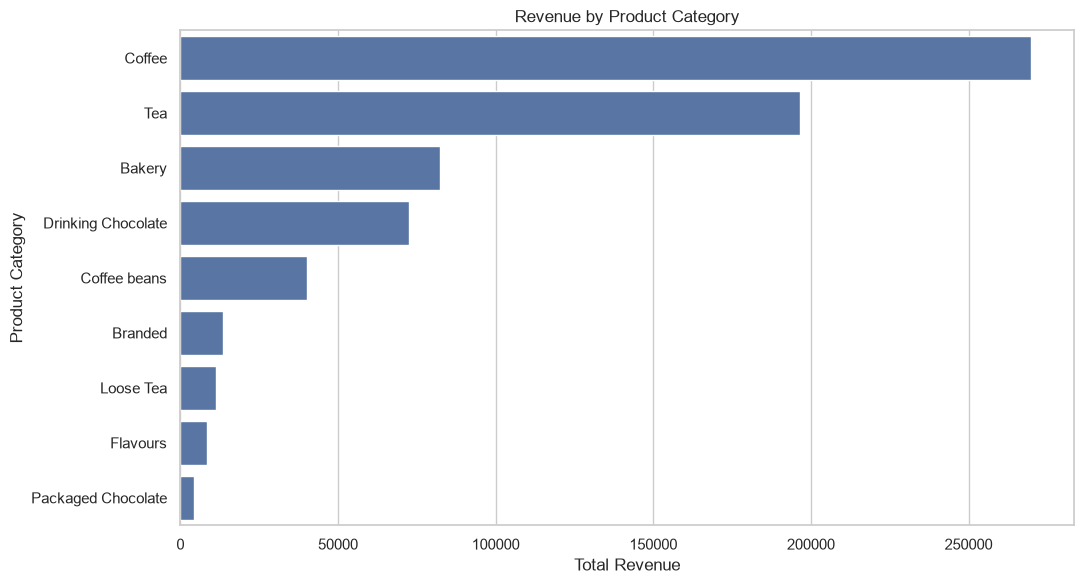

In [50]:

# Sort categories from highest to lowest revenue
category_revenue_chart = category_sales.sort_values(
    by='total_revenue',
    ascending=False
)

# Create the category revenue comparison chart
plt.figure(figsize=(11, 6))

sns.barplot(
    data=category_revenue_chart,
    x='total_revenue',
    y='product_category',
    order=category_revenue_chart['product_category']
)

# Add chart title and axis labels
plt.title('Revenue by Product Category')
plt.xlabel('Total Revenue')
plt.ylabel('Product Category')

# Improve spacing and display the chart
plt.tight_layout()
plt.show()

## 17. Store-Level Product Performance

### Objective
The objective of this analysis is to evaluate product category performance across the three store locations: Hell's Kitchen, Astoria, and Lower Manhattan.

### Business Questions
- Which product categories generate the highest revenue at each store?
- Do all three stores have similar product category sales patterns?
- Which categories perform particularly well or poorly at individual locations?
- Are there opportunities to improve product availability and sales at specific stores?

### Methodology
We will group the transaction data by store location and product category. We will calculate total units sold, number of transaction records, and total revenue for each combination.

We will then compare category-level revenue across the three stores using tables and visualizations.

### Business Value
This analysis can help management understand local customer purchasing patterns, improve product assortment decisions, and identify opportunities for store-specific promotions.

**Note:** Revenue indicates sales value, not profit. Product costs and operating expenses are not included in this dataset.

In [51]:
# Group transaction data by store location and product category.
# This allows us to compare category performance across all stores.

store_category_sales = (
    df.groupby(['store_location', 'product_category'])
    .agg(
        # Calculate total quantity of products sold
        total_units_sold=('transaction_qty', 'sum'),

        # Count the number of transaction records
        total_transactions=('transaction_id', 'count'),

        # Calculate total revenue for each store-category combination
        total_revenue=('revenue', 'sum')
    )
    .reset_index()
)

# Sort results by store location and revenue (highest first)
store_category_sales = store_category_sales.sort_values(
    by=['store_location', 'total_revenue'],
    ascending=[True, False]
).reset_index(drop=True)

# Display the results, rounded to two decimal places
store_category_sales.round(2)

,store_location,product_category,total_units_sold,total_transactions,total_revenue
0,Astoria,Coffee,29655,20025,89744.30
1,Astoria,Tea,24048,16260,67839.90
2,Astoria,Bakery,7496,7289,26599.75
3,Astoria,Drinking Chocolate,6351,4300,26335.25
4,Astoria,Coffee beans,502,502,10219.20
5,Astoria,Branded,279,279,5457.00
6,Astoria,Loose Tea,344,344,3194.00
7,Astoria,Flavours,2206,1490,1764.80
8,Astoria,Packaged Chocolate,110,110,1089.71
9,Hell's Kitchen,Coffee,30220,20187,91222.65


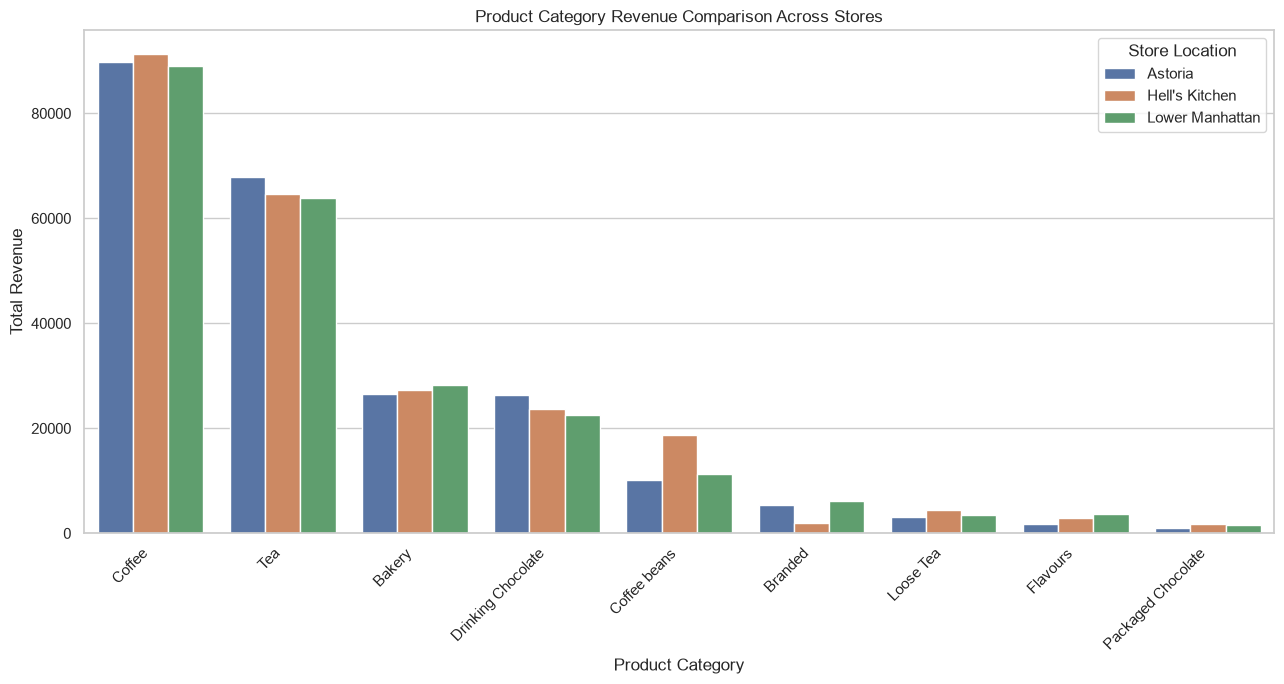

In [52]:
# Create a grouped bar chart to compare category revenue across stores.

plt.figure(figsize=(13, 7))

sns.barplot(
    data=store_category_sales,
    x='product_category',
    y='total_revenue',
    hue='store_location'
)

# Add chart title and axis labels
plt.title('Product Category Revenue Comparison Across Stores')
plt.xlabel('Product Category')
plt.ylabel('Total Revenue')

# Rotate category labels for better readability
plt.xticks(rotation=45, ha='right')

# Display the legend
plt.legend(title='Store Location')

# Adjust layout and display chart
plt.tight_layout()
plt.show()

## 18. Revenue Concentration and Pareto Analysis

### Objective
The objective of this analysis is to understand how revenue is distributed across the 80 products and determine whether a small number of products contribute a significant proportion of total revenue.

### Business Questions
- Which products contribute the most to total revenue?
- What percentage of total revenue is generated by the top 20% of products?
- How many products are required to generate 80% of total revenue?
- Is the business heavily dependent on a small group of products?

### Methodology
We will use Pareto Analysis to rank products based on revenue contribution.

The analysis will include:
- Sorting products from highest to lowest revenue.
- Calculating individual revenue contribution percentages.
- Calculating cumulative revenue contribution.
- Identifying the number of products required to reach 80% of total revenue.
- Visualizing cumulative revenue contribution using a Pareto chart.

### Business Value
This analysis can help management identify key revenue-generating products, prioritize inventory management, and make informed decisions about product promotions and assortment planning.

**Note:** Pareto analysis identifies revenue concentration, not product profitability. Cost and profit information are not available in this dataset.

In [56]:
# Create a copy of the product sales DataFrame.
# This keeps our original product_sales DataFrame unchanged.

pareto_analysis = product_sales.copy()

# Sort products from highest to lowest total revenue.
pareto_analysis = pareto_analysis.sort_values(
    by='total_revenue',
    ascending=False
).reset_index(drop=True)

# Calculate each product's percentage contribution to total revenue.
pareto_analysis['revenue_contribution_pct'] = (
    pareto_analysis['total_revenue'] / total_revenue
) * 100

# Calculate cumulative revenue contribution.
# The cumulative sum shows how much revenue is generated
# by the top products as we move down the ranked list.

pareto_analysis['cumulative_revenue_pct'] = (
    pareto_analysis['revenue_contribution_pct'].cumsum()
)

# Create a product rank starting from 1.
pareto_analysis['product_rank'] = (
    pareto_analysis.index + 1
)

# Display the first 15 products in the Pareto analysis.
pareto_analysis[
    [
        'product_rank',
        'product_detail',
        'total_revenue',
        'revenue_contribution_pct',
        'cumulative_revenue_pct'
    ]
].head(40).round(2)

,product_rank,product_detail,total_revenue,revenue_contribution_pct,cumulative_revenue_pct
0,1,Sustainably Grown Organic Lg,21151.75,3.03,3.03
1,2,Dark chocolate Lg,21006.00,3.01,6.03
2,3,Latte Rg,19112.25,2.73,8.77
3,4,Cappuccino Lg,17641.75,2.52,11.29
4,5,Morning Sunrise Chai Lg,17384.00,2.49,13.78
5,6,Latte,17257.50,2.47,16.25
6,7,Jamaican Coffee River Lg,16481.25,2.36,18.61
7,8,Sustainably Grown Organic Rg,16233.75,2.32,20.93
8,9,Cappuccino,15997.50,2.29,23.22
9,10,Brazilian Lg,15109.50,2.16,25.38


In [57]:
# Find the first product rank where cumulative revenue
# contribution reaches or exceeds 80%.

products_for_80 = pareto_analysis[
    pareto_analysis['cumulative_revenue_pct'] >= 80
].iloc[0]

# Extract the product rank and cumulative revenue percentage.
number_of_products_80 = products_for_80['product_rank']
cumulative_revenue_80 = products_for_80['cumulative_revenue_pct']

# Calculate the percentage of all products required.
total_products = len(pareto_analysis)

product_percentage = (
    number_of_products_80 / total_products
) * 100

# Display the results.
print("Total number of products:", total_products)

print(
    "Number of products required to reach 80% revenue:",
    number_of_products_80
)

print(
    "Cumulative revenue contribution:",
    round(cumulative_revenue_80, 2), "%"
)

print(
    "Percentage of products contributing to 80% revenue:",
    round(product_percentage, 2), "%"
)

Total number of products: 80
Number of products required to reach 80% revenue: 43
Cumulative revenue contribution: 80.52 %
Percentage of products contributing to 80% revenue: 53.75 %


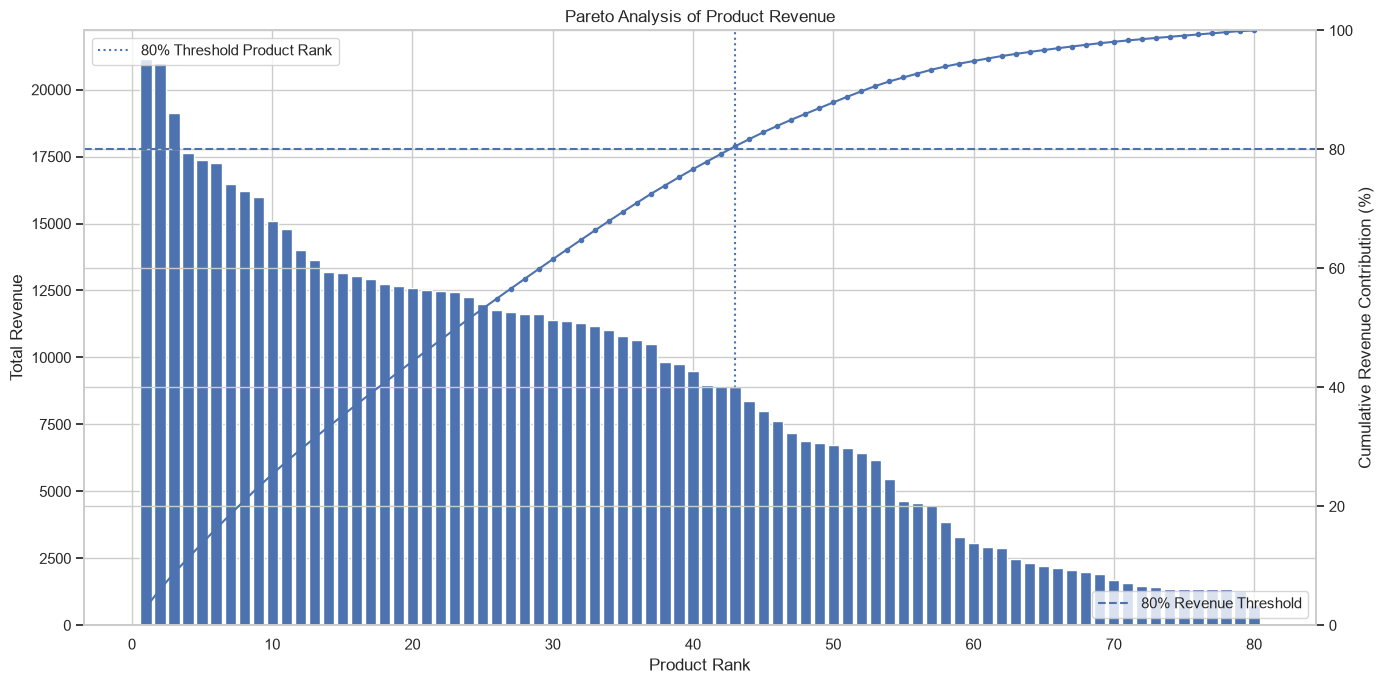

In [59]:
# Create a figure with two y-axes for the Pareto chart.
fig, ax1 = plt.subplots(figsize=(14, 7))

# Plot individual product revenue as bars.
ax1.bar(
    pareto_analysis['product_rank'],
    pareto_analysis['total_revenue']
)

# Add labels for the primary y-axis.
ax1.set_xlabel('Product Rank')
ax1.set_ylabel('Total Revenue')
ax1.set_title('Pareto Analysis of Product Revenue')

# Create a second y-axis for cumulative revenue percentage.
ax2 = ax1.twinx()

# Plot cumulative revenue contribution as a line.
ax2.plot(
    pareto_analysis['product_rank'],
    pareto_analysis['cumulative_revenue_pct'],
    marker='o',
    markersize=3
)

# Add labels for the secondary y-axis.
ax2.set_ylabel('Cumulative Revenue Contribution (%)')

# Add an 80% reference line.
ax2.axhline(
    y=80,
    linestyle='--',
    label='80% Revenue Threshold'
)

# Mark the number of products needed to reach 80%.
ax1.axvline(
    x=number_of_products_80,
    linestyle=':',
    label='80% Threshold Product Rank'
)

# Set the cumulative percentage axis from 0 to 100.
ax2.set_ylim(0, 100)

# Display legends for both axes.
ax1.legend(loc='upper left')
ax2.legend(loc='lower right')

# Improve layout and display the chart.
plt.tight_layout()
plt.show()

### Conclusion: Revenue Concentration and Pareto Analysis

The Pareto analysis revealed that revenue is distributed across a relatively broad range of products.

Out of 80 products, 43 products (53.75%) contribute approximately 80.52% of total revenue. The top 10 products contribute 25.38% of total revenue.

These findings indicate that the business does not depend exclusively on a small group of products to generate sales. A broader product portfolio contributes meaningfully to overall revenue.

Management should prioritize the availability of leading products while continuing to monitor and improve the performance of the remaining product range.

**Business takeaway:** Maintaining a balanced and well-managed product portfolio is important for sustaining revenue performance.

## 19. Key Business Insights and Findings

### Objective
The objective of this section is to consolidate the findings from the exploratory data analysis and product performance analysis to identify the most important business insights for Afficionado Coffee Roasters.

### Areas of Analysis
The key findings will be summarized across the following areas:

1. **Product Performance:** Identify the products generating the highest and lowest sales and revenue.
2. **Revenue Contribution:** Understand which products and categories contribute most to overall revenue.
3. **Category Performance:** Evaluate the performance of Coffee, Tea, Bakery, and other product categories.
4. **Store Performance:** Compare revenue generation across the three store locations.
5. **Time-Based Performance:** Identify peak business hours and periods of lower sales activity.
6. **Pricing Analysis:** Understand how average revenue per unit varies across products.
7. **Revenue Concentration:** Evaluate how revenue is distributed across the product portfolio using Pareto Analysis.

### Business Value
These insights will help management understand sales patterns, identify growth opportunities, improve inventory planning, and make more informed product and marketing decisions.

### Analysis Limitation
The dataset contains transaction-level sales information but does not include product costs, profit margins, customer demographics, or transaction dates. Therefore, conclusions will focus on revenue and sales performance rather than profitability or customer behavior.

In [60]:
# Create a summary dictionary containing the key business metrics.

key_metrics = {
    'Metric': [
        'Total Revenue',
        'Total Transaction Records',
        'Total Units Sold',
        'Total Products',
        'Total Product Categories',
        'Total Store Locations',
        'Top Revenue Category',
        'Top Revenue Store',
        'Peak Revenue Hour',
        'Products Required for 80% Revenue'
    ],

    'Result': [
        round(df['revenue'].sum(), 2),
        df['transaction_id'].count(),
        df['transaction_qty'].sum(),
        df['product_id'].nunique(),
        df['product_category'].nunique(),
        df['store_id'].nunique(),
        category_sales.iloc[0]['product_category'],
        store_sales.iloc[0]['store_location'],
        hourly_sales.loc[
            hourly_sales['total_revenue'].idxmax(), 'hour'
        ],
        int(number_of_products_80)
    ]
}

# Convert the dictionary into a DataFrame.
key_metrics_df = pd.DataFrame(key_metrics)

# Display the summary table.
key_metrics_df

,Metric,Result
0,Total Revenue,698812.33
1,Total Transaction Records,149116
2,Total Units Sold,214470
3,Total Products,80
4,Total Product Categories,9
5,Total Store Locations,3
6,Top Revenue Category,Coffee
7,Top Revenue Store,Hell's Kitchen
8,Peak Revenue Hour,10
9,Products Required for 80% Revenue,43


### Key Business Insights

The analysis of Afficionado Coffee Roasters revealed several important business findings:

1. **Strong overall sales performance:** The business generated total revenue of 698,812.33 from 149,116 transaction records and 214,470 units sold.

2. **Coffee and Tea dominate revenue:** Coffee contributes 38.63% and Tea contributes 28.11% of total revenue. Together, they account for 66.74% of overall revenue.

3. **Balanced store performance:** Hell's Kitchen, Astoria, and Lower Manhattan contribute relatively similar shares of total revenue, with Hell's Kitchen ranking first at 33.84%.

4. **Strong morning sales activity:** Revenue peaks at 10:00 AM, suggesting that morning operations are an important part of the business.

5. **Broad product revenue contribution:** Approximately 53.75% of products are required to generate 80.52% of total revenue, indicating that revenue is distributed across a relatively broad product portfolio.

6. **Different product price levels:** Products vary considerably in average revenue per unit, suggesting opportunities to review product positioning and pricing.

### Overall Finding

Afficionado Coffee Roasters has a diversified product portfolio, with Coffee and Tea serving as its primary revenue drivers. The three stores demonstrate relatively balanced revenue performance, while morning hours represent an important sales period.

These findings provide a foundation for improving inventory planning, product assortment, store-level strategies, and marketing decisions.

### 19. Additional Business Performance KPIs

#### 19.1 Business Dependency

**Objective:**

Measure how much the business depends on a limited number of products and product categories to generate its total revenue.

A higher revenue concentration indicates greater dependence on a smaller part of the product portfolio.

We will evaluate business dependency using:

- Revenue contribution from the top 10 products.
- Revenue contribution from the top 20 products.
- Revenue contribution from the top 43 products.
- Combined revenue contribution from Coffee and Tea categories.

These indicators help assess how concentrated the business's revenue is across its product portfolio.

In [62]:
# Calculate revenue contribution from the top 10 products
top_10_dependency = (
    pareto_analysis.head(10)['total_revenue'].sum()
    / total_revenue
) * 100

# Calculate revenue contribution from the top 20 products
top_20_dependency = (
    pareto_analysis.head(20)['total_revenue'].sum()
    / total_revenue
) * 100

# Calculate revenue contribution from the top 43 products
top_43_dependency = (
    pareto_analysis.head(43)['total_revenue'].sum()
    / total_revenue
) * 100

# Calculate combined revenue contribution from Coffee and Tea
coffee_tea_dependency = (
    category_sales[
        category_sales['product_category'].isin(['Coffee', 'Tea'])
    ]['total_revenue'].sum()
    / total_revenue
) * 100

# Display the business dependency KPIs
business_dependency = pd.DataFrame({
    'KPI': [
        'Top 10 Products Revenue Contribution',
        'Top 20 Products Revenue Contribution',
        'Top 43 Products Revenue Contribution',
        'Coffee and Tea Revenue Contribution'
    ],
    'Value (%)': [
        top_10_dependency,
        top_20_dependency,
        top_43_dependency,
        coffee_tea_dependency
    ]
})

business_dependency.round(2)

,KPI,Value (%)
0,Top 10 Products Revenue Contribution,25.38
1,Top 20 Products Revenue Contribution,44.38
2,Top 43 Products Revenue Contribution,80.52
3,Coffee and Tea Revenue Contribution,66.74


#### 19.2 Menu Risk Exposure

**Objective:**

Measure the proportion of products that demonstrate both low sales volume and low revenue contribution.

Products classified as Low Volume, Low Revenue may require further evaluation to determine whether they should be retained, promoted, repriced, or removed from the product portfolio.

**Formula:**

Menu Risk Exposure (%) = (Number of Low Volume, Low Revenue Products / Total Number of Products) × 100

A higher percentage indicates that a larger portion of the product portfolio is performing below the selected volume and revenue benchmarks.

In [63]:
# Count products in the Low Volume, Low Revenue group
low_performance_products = (
    product_performance[
        product_performance['performance_group'] == 'Low Volume, Low Revenue'
    ].shape[0]
)

# Count the total number of products
total_products = product_performance['product_id'].nunique()

# Calculate Menu Risk Exposure as a percentage
menu_risk_exposure = (
    low_performance_products / total_products
) * 100

# Display the KPI results
menu_risk_summary = pd.DataFrame({
    'KPI': [
        'Low Volume, Low Revenue Products',
        'Total Products',
        'Menu Risk Exposure'
    ],
    'Value': [
        low_performance_products,
        total_products,
        round(menu_risk_exposure, 2)
    ]
})

menu_risk_summary

,KPI,Value
0,"Low Volume, Low Revenue Products",38.0
1,Total Products,80.0
2,Menu Risk Exposure,47.5


#### 19.3 Product Efficiency KPI — Revenue per Unit

**Objective:**

Evaluate how much revenue each product generates, on average, for every unit sold.

**Formula:**

Revenue per Unit = Total Product Revenue / Total Units Sold

This KPI helps compare products based on their average revenue per unit and identify products with higher or lower average selling values.

**Note:** Revenue per unit is not the same as profit per unit because product costs and operating expenses are not available in the dataset.

In [64]:
# Create a copy of the product sales summary
product_efficiency = product_sales.copy()

# Calculate average revenue generated per unit sold
product_efficiency['revenue_per_unit'] = (
    product_efficiency['total_revenue']
    / product_efficiency['total_units_sold']
)

# Rank products from highest to lowest revenue per unit
product_efficiency = product_efficiency.sort_values(
    by='revenue_per_unit',
    ascending=False
).reset_index(drop=True)

# Display the top 10 products by revenue per unit
product_efficiency[
    [
        'product_detail',
        'total_units_sold',
        'total_revenue',
        'revenue_per_unit'
    ]
].head(10).round(2)

,product_detail,total_units_sold,total_revenue,revenue_per_unit
0,Civet Cat,260,11700.00,45.00
1,I Need My Bean! T-shirt,221,6163.00,27.89
2,Organic Decaf Blend,206,4657.50,22.61
3,Ethiopia,218,4578.00,21.00
4,Primo Espresso Roast,150,3067.50,20.45
5,Jamacian Coffee River,146,2883.50,19.75
6,Brazilian - Organic,214,3852.00,18.00
7,Our Old Time Diner Blend,183,3294.00,18.00
8,Columbian Medium Roast,148,2220.00,15.00
9,Espresso Roast,169,2492.75,14.75


In [66]:
# Create a consolidated summary of the additional business KPIs
additional_kpi_summary = pd.DataFrame({
    'KPI Name': [
        'Top 10 Products Revenue Contribution',
        'Top 20 Products Revenue Contribution',
        'Top 43 Products Revenue Contribution',
        'Coffee and Tea Revenue Contribution',
        'Menu Risk Exposure',
        'Highest Revenue per Unit Product',
        'Highest Revenue per Unit'
    ],
    'KPI Value': [
        f'{top_10_dependency:.2f}%',
        f'{top_20_dependency:.2f}%',
        f'{top_43_dependency:.2f}%',
        f'{coffee_tea_dependency:.2f}%',
        f'{menu_risk_exposure:.2f}%',
        product_efficiency.iloc[0]['product_detail'],
        round(product_efficiency.iloc[0]['revenue_per_unit'], 2)
    ]
})

additional_kpi_summary

,KPI Name,KPI Value
0,Top 10 Products Revenue Contribution,25.38%
1,Top 20 Products Revenue Contribution,44.38%
2,Top 43 Products Revenue Contribution,80.52%
3,Coffee and Tea Revenue Contribution,66.74%
4,Menu Risk Exposure,47.50%
5,Highest Revenue per Unit Product,Civet Cat
6,Highest Revenue per Unit,45.0


### Popularity vs. Revenue Analysis

#### Objective

Analyze the relationship between product sales volume and revenue generation to identify products that perform differently in terms of popularity and financial contribution.

We will use a scatter plot to compare:

- **X-axis:** Total units sold (product popularity).
- **Y-axis:** Total product revenue.
- **Each point:** One individual product.

This analysis helps identify high-volume products, high-revenue products, and products that may require further business evaluation.

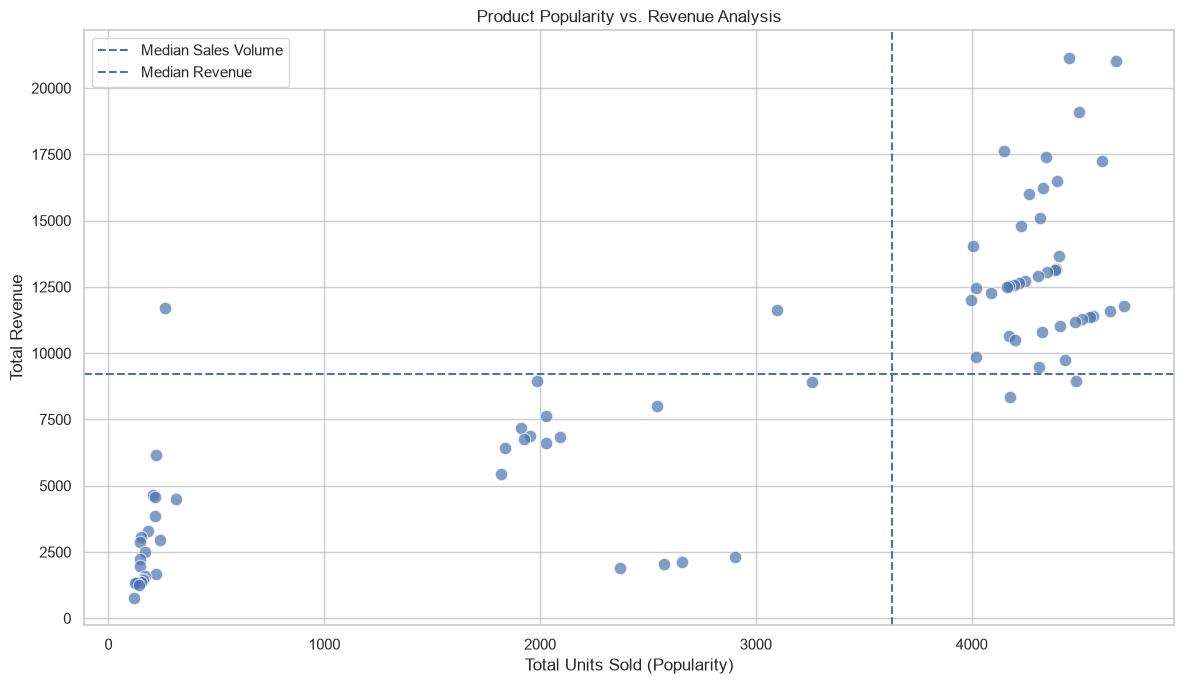

In [67]:
# Create a figure for the scatter plot
plt.figure(figsize=(12, 7))

# Plot each product using its sales volume and total revenue
sns.scatterplot(
    data=product_sales,
    x='total_units_sold',
    y='total_revenue',
    s=80,
    alpha=0.7
)

# Add median reference lines to divide products into four groups
plt.axvline(
    product_sales['total_units_sold'].median(),
    linestyle='--',
    label='Median Sales Volume'
)

plt.axhline(
    product_sales['total_revenue'].median(),
    linestyle='--',
    label='Median Revenue'
)

# Add chart title and axis labels
plt.title('Product Popularity vs. Revenue Analysis')
plt.xlabel('Total Units Sold (Popularity)')
plt.ylabel('Total Revenue')

# Display the legend and improve layout
plt.legend()
plt.tight_layout()

# Display the chart
plt.show()

####  Key Insights and Business Interpretation

The scatter plot compares product popularity, measured by total units sold, with financial performance, measured by total revenue.

The analysis classifies 80 products into four performance groups using median sales volume of 3,629.5 units and median product revenue of 9,225.

- 38 products (47.5%) fall into the High Volume, High Revenue group.
- 38 products (47.5%) fall into the Low Volume, Low Revenue group.
- 2 products (2.5%) fall into the Low Volume, High Revenue group.
- 2 products (2.5%) fall into the High Volume, Low Revenue group.

The findings demonstrate that product popularity and revenue contribution should be evaluated together. Products with strong performance in both measures should be prioritized, while lower-performing products should be reviewed before making assortment decisions.

**Conclusion:** The popularity vs. revenue analysis provides a useful foundation for product ranking, portfolio evaluation, and interactive product performance comparisons.

## 20. Key Business Insights and Findings

The analysis of 149,116 transaction records from Afficionado Coffee Roasters revealed several important findings regarding product sales, revenue contribution, category performance, store performance, pricing, and sales timing.

### 20.1 Overall Business Performance

The business generated total revenue of **698,812.33** from **149,116 transaction records**, selling a total of **214,470 units** across 80 products and 9 product categories.

This provides a substantial transaction base for evaluating product and store performance.

### 20.2 Product-Level Revenue Performance

The highest-revenue product was **Sustainably Grown Organic Lg**, generating **21,151.75**, equivalent to 3.03% of total revenue.

It was followed by:
- Dark chocolate Lg: 21,006.00 (3.01%)
- Latte Rg: 19,112.25 (2.73%)
- Cappuccino Lg: 17,641.75 (2.52%)
- Morning Sunrise Chai Lg: 17,384.00 (2.49%)

These five products collectively contributed approximately **13.78% of total revenue**.

In terms of sales volume, **Earl Grey Rg** ranked first with 4,708 units sold, while Sustainably Grown Organic Lg generated the highest revenue. This demonstrates that product popularity and revenue contribution do not always follow the same ranking.

### 20.3 Product Category Performance

Coffee was the leading product category, generating **269,952.45**, or **38.63% of total revenue**.

Tea ranked second with **196,405.95**, contributing **28.11%**.

Together, Coffee and Tea generated **466,358.40**, representing **66.74% of total revenue**.

Bakery contributed 82,315.64 (11.78%), while Drinking Chocolate generated 72,416.00 (10.36%).

These results establish Coffee and Tea as the primary revenue-generating categories.

### 20.4 Store-Level Performance

Among the three store locations, Hell's Kitchen generated the highest revenue at **236,511.17 (33.84%)**.

Astoria generated 232,243.91 (33.23%), while Lower Manhattan generated 230,057.25 (32.92%).

The difference between the highest- and lowest-performing stores was only **6,453.92**.

This indicates a relatively balanced revenue distribution across the three locations.

### 20.5 Time-Based Sales Performance

The highest revenue was recorded at **10:00 AM**, generating **88,673.39**, equivalent to **12.69% of total revenue**.

During this hour, 26,713 units were sold across 18,545 transaction records.

The period between 8:00 AM and 10:00 AM represented a particularly strong sales window, suggesting that morning operations play an important role in overall business performance.

### 20.6 Product Pricing Analysis

Civet Cat recorded the highest average revenue per unit at **45.00**, followed by I Need My Bean! T-shirt at 27.89 and Organic Decaf Blend at 22.61.

At the lower end, Carmel syrup, Chocolate syrup, Hazelnut syrup, and Sugar Free Vanilla syrup each recorded an average revenue per unit of 0.80.

These differences demonstrate the variety of price points across the product portfolio.

### 20.7 Revenue Concentration Analysis

The Pareto analysis showed that:
- The top 10 products contributed 25.38% of revenue.
- The top 20 products contributed 44.38%.
- The top 40 products contributed 76.68%.
- 43 out of 80 products (53.75%) generated approximately 80.52% of total revenue.

This indicates that revenue is distributed across a relatively broad product portfolio rather than being concentrated in only a small number of products.

### 20.8 Overall Business Assessment

The analysis identifies Coffee and Tea as the dominant revenue categories, Sustainably Grown Organic Lg as the highest-revenue individual product, and Hell's Kitchen as the highest-revenue store.

The business also demonstrates relatively balanced store-level revenue and a strong morning sales period.

These findings provide a numerical foundation for inventory planning, product assortment decisions, pricing reviews, and store-level operational improvements.

**Data limitation:** This analysis evaluates sales volume and revenue. Since product costs, operating expenses, and profit margins are unavailable, it does not establish which products or stores are the most profitable.

## 21. Business Recommendations

Based on the findings from the product, category, store, pricing, and time-based analyses, the following recommendations are proposed for Afficionado Coffee Roasters.

### 21.1 Strengthen Inventory Management for High-Revenue Products

Sustainably Grown Organic Lg generated the highest product revenue of 21,151.75, followed by Dark chocolate Lg at 21,006.00 and Latte Rg at 19,112.25.

**Recommendation:** Prioritize stock monitoring and replenishment planning for these high-revenue products to reduce the risk of stock shortages. Also monitor high-volume products such as Earl Grey Rg, which sold 4,708 units.

### 21.2 Prioritize Coffee and Tea Categories

Coffee generated 269,952.45 (38.63% of revenue), while Tea generated 196,405.95 (28.11%). Together, they contributed 66.74% of total revenue.

**Recommendation:** Maintain a strong assortment of Coffee and Tea products, monitor their availability, and explore complementary promotions with Bakery and Drinking Chocolate products.

### 21.3 Develop Store-Specific Product Strategies

Hell's Kitchen generated the highest store revenue at 236,511.17. It also generated 18,635.10 in Coffee beans revenue, compared with 10,219.20 in Astoria and 11,230.95 in Lower Manhattan.

Lower Manhattan generated the highest Bakery revenue at 28,328.94.

**Recommendation:** Investigate the product mix and customer purchasing patterns behind these differences. Consider testing stronger Coffee beans promotions in Astoria and Lower Manhattan and evaluating the Bakery assortment at Hell's Kitchen.

### 21.4 Optimize Staffing and Inventory During Peak Hours

The highest revenue was recorded at 10:00 AM, reaching 88,673.39 or 12.69% of total revenue. The 8:00 AM to 10:00 AM period showed particularly strong sales activity.

**Recommendation:** Review staffing schedules and inventory replenishment procedures to ensure sufficient operational capacity during the morning peak period.

### 21.5 Review Product Pricing and Positioning

Civet Cat recorded an average revenue per unit of 45.00, while several syrup products, including Carmel syrup and Chocolate syrup, averaged 0.80 per unit.

**Recommendation:** Review product positioning and pricing using demand, product costs, and customer purchasing patterns. Avoid changing prices based solely on average revenue per unit.

### 21.6 Monitor the Wider Product Portfolio

The Pareto analysis showed that 43 out of 80 products generated approximately 80.52% of total revenue.

**Recommendation:** Prioritize monitoring of these 43 products while continuing to evaluate the remaining 37 products. Products with low sales should be reviewed for pricing, demand, promotions, and assortment suitability before considering discontinuation.

### 21.7 Improve Data-Driven Decision-Making

The current analysis provides useful information about revenue, units sold, and transaction timing, but it does not include product costs, customer demographics, or transaction dates.

**Recommendation:** Introduce product cost and margin tracking, customer-level insights where appropriately collected, and transaction date information. These additions would support more detailed profitability, customer behavior, and seasonal sales analysis.

### Expected Business Impact

Implementing these recommendations could help Afficionado Coffee Roasters improve stock availability, strengthen its leading product categories, optimize store operations, and make better-informed assortment and pricing decisions.

The recommendations should be evaluated through future sales and profitability measurements before being treated as proven improvements.

## 21. Business Recommendations

### Objective
The objective of this section is to convert the findings from the sales and product performance analysis into practical business recommendations for Afficionado Coffee Roasters.

### Areas for Improvement

1. **Product and Inventory Management:** Maintain sufficient stock of high-revenue products while reviewing the performance of low-selling products.

2. **Category-Level Strategy:** Prioritize Coffee and Tea because they contribute 66.74% of total revenue. Explore cross-selling opportunities with Bakery and Drinking Chocolate.

3. **Store-Level Optimization:** Develop store-specific product strategies based on differences in category performance across Hell's Kitchen, Astoria, and Lower Manhattan.

4. **Pricing and Product Positioning:** Review the pricing and sales performance of products with different average revenue per unit to identify opportunities for better product positioning.

5. **Peak-Hour Operations:** Ensure adequate staffing and inventory availability during the morning peak, particularly around 8:00 AM to 10:00 AM.

6. **Product Portfolio Optimization:** Monitor products with low sales and revenue contributions to identify opportunities for promotions, product improvements, or assortment adjustments.

### Expected Business Benefits
Implementing these recommendations may help improve inventory efficiency, strengthen product sales, optimize store operations, and support sustainable revenue growth.

**Note:** These recommendations are based on revenue and transaction patterns. Profitability and cost data should be evaluated before making major pricing, inventory, or product-discontinuation decisions.

## 22. Project Conclusion

This project involved a comprehensive analysis of transaction-level sales data from Afficionado Coffee Roasters to evaluate product performance, revenue contribution, category performance, store performance, pricing patterns, and sales timing.

The analysis covered **149,116 transaction records**, **214,470 units sold**, **80 products**, **9 product categories**, and **3 store locations**, generating total revenue of **698,812.33**.

The findings identified several important business patterns.

**Coffee and Tea emerged as the primary revenue-generating categories**, contributing 38.63% and 28.11% of total revenue, respectively. Together, they accounted for 66.74% of overall revenue.

At the individual product level, **Sustainably Grown Organic Lg** generated the highest revenue of 21,151.75, followed by Dark chocolate Lg at 21,006.00. In terms of sales volume, Earl Grey Rg ranked first with 4,708 units sold.

Among the three locations, **Hell's Kitchen generated the highest revenue of 236,511.17**, followed by Astoria and Lower Manhattan. However, the relatively small difference between store revenues indicates balanced sales performance across the locations.

The time-based analysis identified **10:00 AM as the highest-revenue hour**, generating 88,673.39, or 12.69% of total revenue. This highlights the importance of morning operations in the overall sales pattern.

The Pareto analysis further revealed that 43 out of 80 products contributed approximately 80.52% of total revenue, indicating that revenue is distributed across a relatively broad product portfolio.

Based on these findings, recommendations were developed to strengthen inventory management, prioritize high-performing categories, evaluate store-specific product strategies, optimize peak-hour operations, and improve product-level decision-making.

### Final Conclusion

The analysis demonstrates how transaction-level sales data can be transformed into meaningful business insights. By identifying leading products, revenue-generating categories, store-level differences, and peak sales hours, Afficionado Coffee Roasters can use its historical sales information to support more informed operational and strategic decisions.

Although the analysis provides a strong understanding of sales and revenue performance, incorporating product costs, profit margins, customer information, and transaction dates in future analysis would enable a more comprehensive evaluation of business performance.

Overall, this project establishes a data-driven foundation for improving product management, operational efficiency, and future revenue growth opportunities.

## 23. Final Project Summary

### Project Title
**Product Optimization & Revenue Contribution Analysis for Afficionado Coffee Roasters**

### Project Overview
This project focuses on analyzing transaction-level sales data from Afficionado Coffee Roasters to identify product performance patterns, revenue contribution, category trends, store-level performance, and opportunities for business optimization.

The analysis was conducted using Python, Pandas, NumPy, Matplotlib, and Seaborn.

### Dataset Overview
- Total transaction records: 149,116
- Total units sold: 214,470
- Total products: 80
- Product categories: 9
- Store locations: 3
- Total revenue: 698,812.33

### Key Findings
- Coffee contributed 38.63% of total revenue, followed by Tea at 28.11%.
- Sustainably Grown Organic Lg was the highest-revenue product, generating 21,151.75.
- Hell's Kitchen was the highest-revenue store, generating 236,511.17.
- 10:00 AM was the peak revenue hour, contributing 88,673.39.
- 43 out of 80 products generated approximately 80.52% of total revenue.

### Tools and Technologies
- Python
- Pandas
- NumPy
- Matplotlib
- Seaborn
- Jupyter Notebook

### Skills Demonstrated
- Data cleaning and preprocessing
- Exploratory Data Analysis (EDA)
- Data aggregation and transformation
- Product and category performance analysis
- Revenue contribution analysis
- Store-level comparative analysis
- Time-based sales analysis
- Pricing and average revenue per unit analysis
- Pareto analysis
- Data visualization
- Business insight generation and recommendations

### Project Outcome
The project transformed raw transaction data into actionable business insights, identifying key revenue-generating products and categories, comparing store performance, and highlighting important sales patterns.

The findings provide a foundation for better inventory planning, product assortment decisions, store-level strategies, and operational improvements.